# Brain Tumour Classification.

In [1]:
import os
print(os.listdir("/kaggle/input"))


['btc-algo']


# Seprating the traing and testing dataset into differnt variables.

In [2]:
train_dir = "/kaggle/input/btc-algo/Training"
test_dir  = "/kaggle/input/btc-algo/Testing"


# Printing the name of folders at the given locations.

In [3]:
import os

print("Inside /kaggle/input/:")
print(os.listdir("/kaggle/input"))

print("\nInside /kaggle/input/btc-algo/:")
print(os.listdir("/kaggle/input/btc-algo"))


Inside /kaggle/input/:
['btc-algo']

Inside /kaggle/input/btc-algo/:
['Training', 'Testing']


# Creating data genrator.

In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224) #resizing the images to this pixels
BATCH_SIZE = 32  #processing the 32 images at a time instead of one by one

# Create the generator
train_datagen = ImageDataGenerator(
    rescale=1./255, #image pixel rescaling from [0,255] -> [0,1]
    validation_split=0.2 #reserving 20% for validation
)

test_datagen = ImageDataGenerator(rescale=1./255)



2026-05-08 19:24:43.869041: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778268284.055556      18 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778268284.108493      18 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


# Load traing dataset.

In [5]:
# Use train_datagen (not train_dir!)
train_ds = train_datagen.flow_from_directory(
    train_dir,                  # <-- this is string path
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training"
)

Found 4571 images belonging to 4 classes.


# Loading the test dataset.

In [6]:

test_ds = test_datagen.flow_from_directory(
    test_dir,                   # <-- also a string path
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 1311 images belonging to 4 classes.


# Preprocessing the datasets.

In [7]:
from tensorflow.keras import layers, models
import tensorflow as tf
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical" #performing one hot encoding [0 0 1 0]
)

raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

Found 5712 files belonging to 4 classes.


I0000 00:00:1778268299.479017      18 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Found 1311 files belonging to 4 classes.


# Normalizing the dataset.

In [8]:
class_names = raw_train_ds.class_names
print("Class names:", class_names)

# Normalization
normalization_layer = layers.Rescaling(1./255)
train_ds = raw_train_ds.map(lambda x, y: (normalization_layer(x), y))  #.map()-applies the function to every batch
test_ds  = raw_test_ds.map(lambda x, y: (normalization_layer(x), y))  # normalization() - rescales the images.

Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']


# Model Building using ResNet50.

In [9]:
from tensorflow.keras.applications import ResNet50

base_model = ResNet50(weights="imagenet", include_top=False, input_shape=(224,224,3)) #height,width, RGB channels
base_model.trainable = False  # Freeze base layers

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

# Model training.

In [10]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=50   # Increase for better accuracy
)


Epoch 1/50


I0000 00:00:1778268313.680970      78 service.cc:148] XLA service 0x798564002ba0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778268313.681732      78 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1778268315.357106      78 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/179 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.1667 - loss: 1.9142  

I0000 00:00:1778268319.228183      78 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


179/179 ━━━━━━━━━━━━━━━━━━━━ 36s 117ms/step - accuracy: 0.3987 - loss: 1.3142 - val_accuracy: 0.5423 - val_loss: 1.1464
Epoch 2/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.5369 - loss: 1.0657 - val_accuracy: 0.6011 - val_loss: 1.0694
Epoch 3/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.5833 - loss: 0.9888 - val_accuracy: 0.6377 - val_loss: 0.9622
Epoch 4/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.6152 - loss: 0.9381 - val_accuracy: 0.6644 - val_loss: 0.9413
Epoch 5/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.6347 - loss: 0.8875 - val_accuracy: 0.6621 - val_loss: 0.8751
Epoch 6/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.6656 - loss: 0.8345 - val_accuracy: 0.6712 - val_loss: 0.8459
Epoch 7/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.6519 - loss: 0.8407 - val_accuracy: 0.6804 - val_loss: 0.8378
Epoch 8/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.6817 - loss: 0.7858 - val_accura

# Ploting epoch vs accuracy.

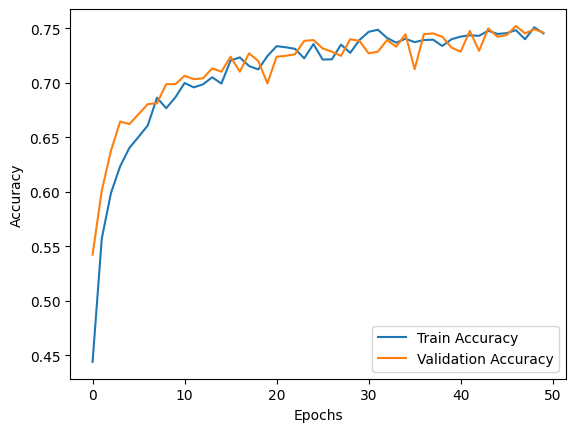

In [11]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot of Train loss vs Val Loss.

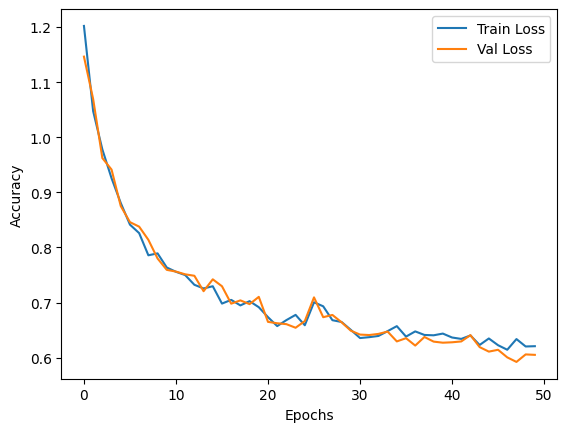

In [12]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Confusion Matrix.

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━

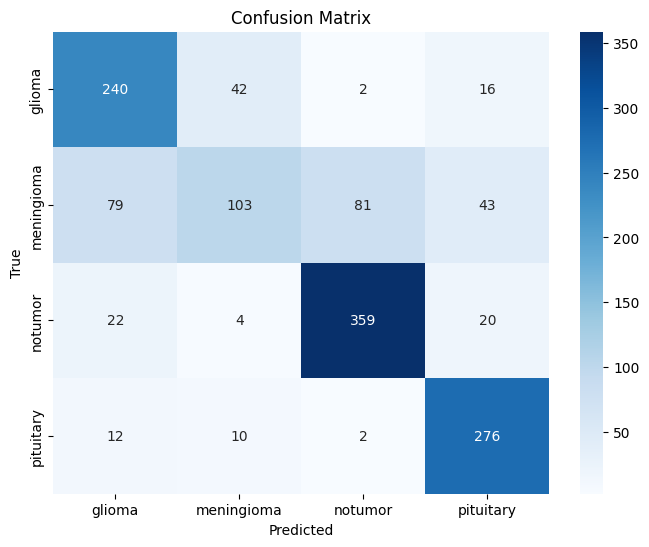

In [13]:
import numpy as np
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Classification Report.

In [14]:
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      glioma       0.68      0.80      0.74       300
  meningioma       0.65      0.34      0.44       306
     notumor       0.81      0.89      0.85       405
   pituitary       0.78      0.92      0.84       300

    accuracy                           0.75      1311
   macro avg       0.73      0.74      0.72      1311
weighted avg       0.73      0.75      0.73      1311



# Metrics:

In [15]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average="weighted")
rec = recall_score(y_true, y_pred, average="weighted")
f1 = f1_score(y_true, y_pred, average="weighted")

print("Accuracy:", acc)
print("Precision:", prec)
print("Recall:", rec)
print("F1 Score:", f1)

Accuracy: 0.7459954233409611
Precision: 0.7344760286773427
Recall: 0.7459954233409611
F1 Score: 0.7257171819518903


# Testing for Images.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


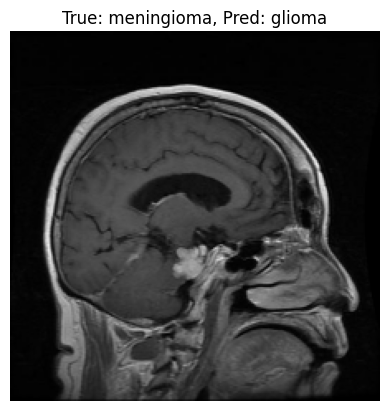

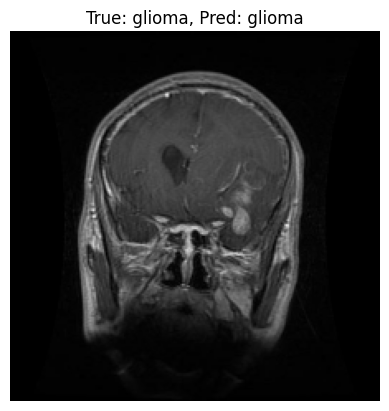

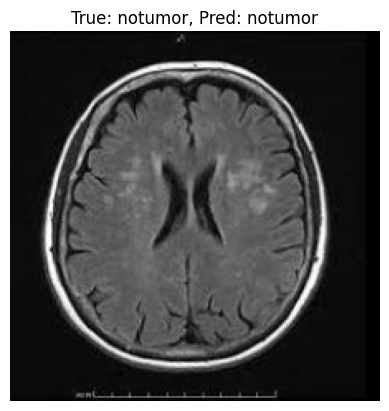

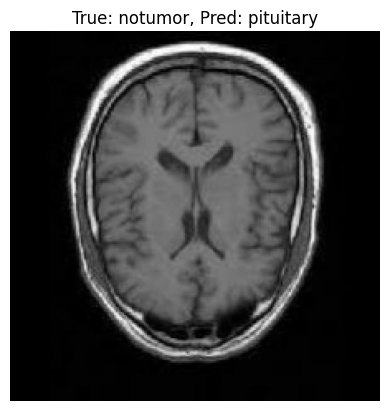

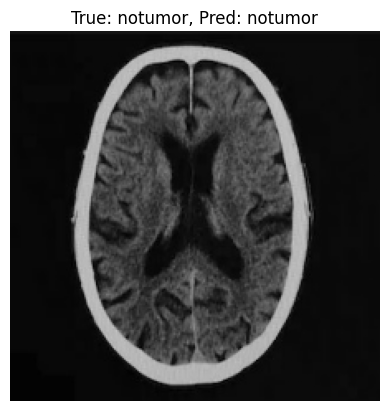

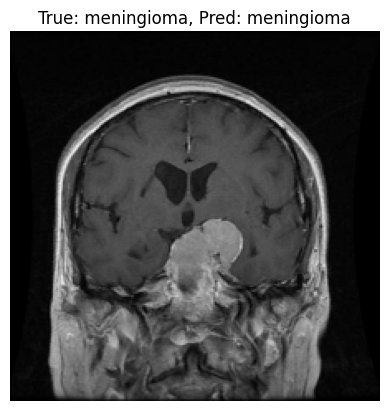

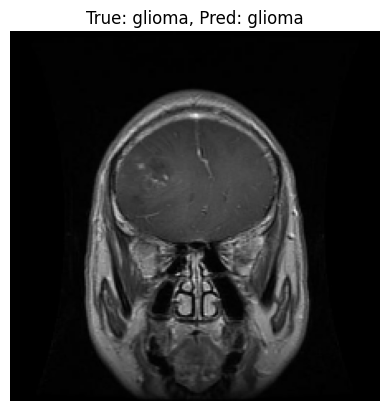

In [16]:
for images, labels in test_ds.take(1):
    preds = model.predict(images)
    for i in range(7):  # show 7 samples
        plt.imshow(images[i].numpy())
        plt.title(f"True: {class_names[np.argmax(labels[i])]}, Pred: {class_names[np.argmax(preds[i])]}")
        plt.axis("off")
        plt.show()

# Unfreezing and Fine tuning the base model.

In [17]:
# Keep all layers frozen by default
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze from a specific point onwards
set_trainable = False
for layer in base_model.layers:
    if layer.name == "conv5_block1_out":   # layer near the last block
        set_trainable = True
    if set_trainable:
        layer.trainable = True


# Building the model for small learning rate. 

In [18]:
from tensorflow.keras.optimizers import Adam

model.compile(optimizer=Adam(learning_rate=1e-5),  # smaller LR
              loss="categorical_crossentropy",
              metrics=["accuracy"])


In [19]:
history_finetune = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10  # 5–10 epochs is usually enough for fine-tuning
)


Epoch 1/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 43s 129ms/step - accuracy: 0.5421 - loss: 11.1137 - val_accuracy: 0.3623 - val_loss: 13.7272
Epoch 2/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.7085 - loss: 0.8711 - val_accuracy: 0.5423 - val_loss: 1.6100
Epoch 3/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.7592 - loss: 0.6184 - val_accuracy: 0.8131 - val_loss: 0.4692
Epoch 4/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.7906 - loss: 0.5152 - val_accuracy: 0.8452 - val_loss: 0.3858
Epoch 5/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.7949 - loss: 0.4797 - val_accuracy: 0.8490 - val_loss: 0.3550
Epoch 6/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.8224 - loss: 0.4285 - val_accuracy: 0.8413 - val_loss: 0.3964
Epoch 7/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.8264 - loss: 0.3993 - val_accuracy: 0.8764 - val_loss: 0.3106
Epoch 8/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.8363 - loss: 0.3797

# Plot epoch vc accuracy

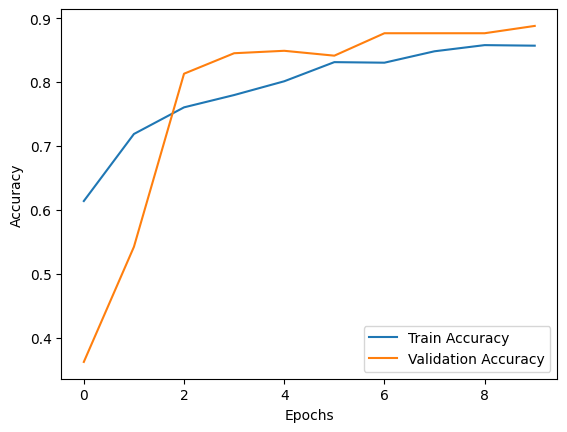

In [20]:
plt.plot(history_finetune.history['accuracy'], label='Train Accuracy')
plt.plot(history_finetune.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Confusion Matrix:

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━

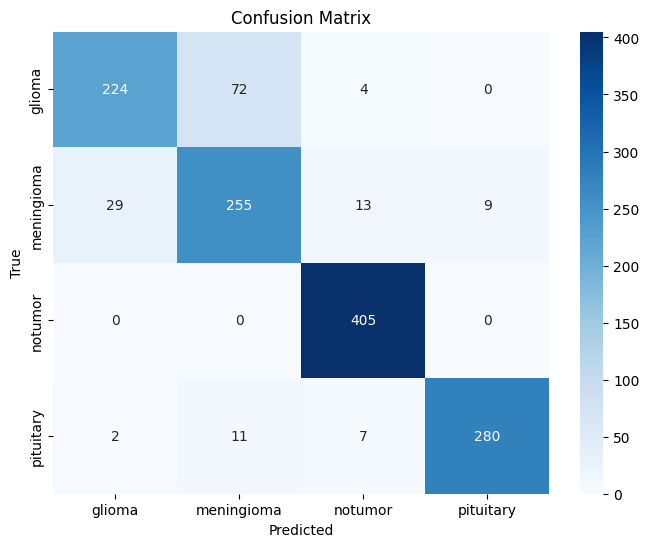

In [21]:
import numpy as np
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Classification report:

In [22]:
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      glioma       0.88      0.75      0.81       300
  meningioma       0.75      0.83      0.79       306
     notumor       0.94      1.00      0.97       405
   pituitary       0.97      0.93      0.95       300

    accuracy                           0.89      1311
   macro avg       0.89      0.88      0.88      1311
weighted avg       0.89      0.89      0.89      1311



# Testing for images :

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


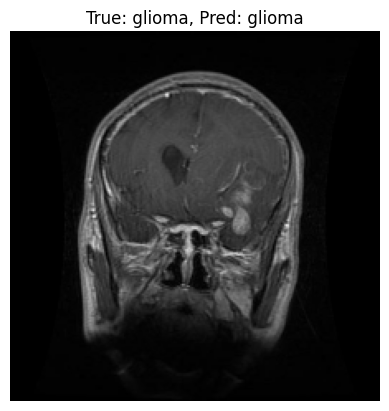

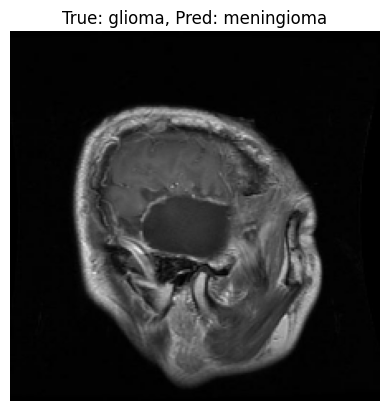

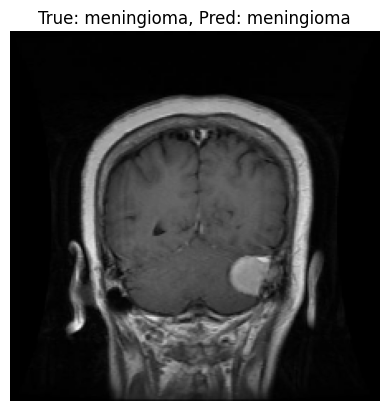

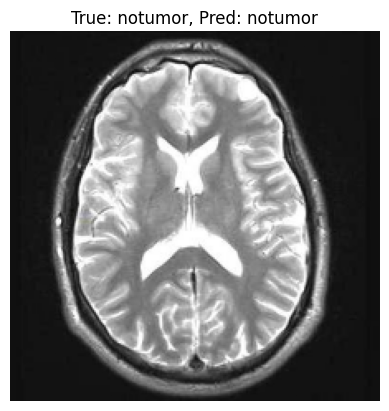

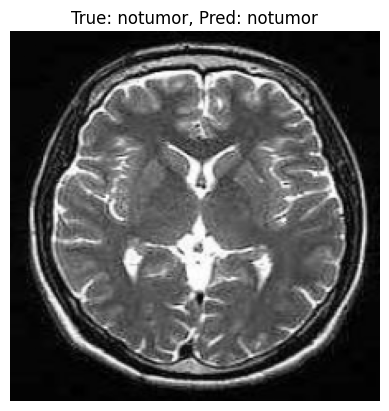

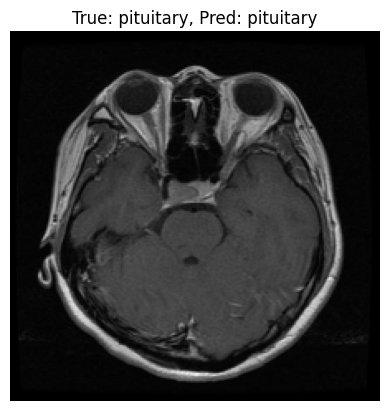

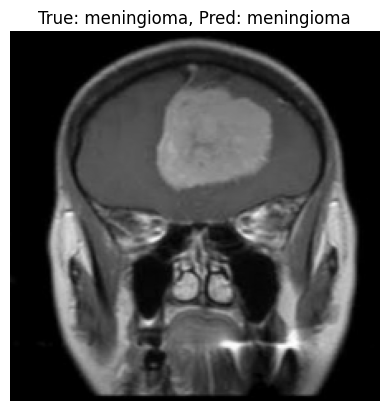

In [23]:
for images, labels in test_ds.take(1):
    preds = model.predict(images)
    for i in range(7):  # show 7 samples
        plt.imshow(images[i].numpy())
        plt.title(f"True: {class_names[np.argmax(labels[i])]}, Pred: {class_names[np.argmax(preds[i])]}")
        plt.axis("off")
        plt.show()

# Building the model using InceptionV3.

In [24]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras import layers, models

# Load InceptionV3 base model
base_model_incep = InceptionV3(
    weights="imagenet", 
    include_top=False, 
    input_shape=(224, 224, 3)   # you can also try (299, 299, 3) since Inception prefers that
)

# Freeze base model layers
base_model_incep.trainable = False

# Build the model
model_incep = models.Sequential([
    base_model_incep,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax")
])

# Compile
model_incep.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Model summary
model_incep.summary()


87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,065,572 (84.17 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

# Training the inception model.

In [25]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Define callbacks
early_stop = EarlyStopping(
    monitor="val_loss",     # monitor validation loss
    patience=5,             # stop if no improvement for 5 epochs
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_incep_model.h5",  # file to save the best model
    monitor="val_accuracy", # save based on validation accuracy
    save_best_only=True,
    verbose=1
)

# Now fit with callbacks
history_incep = model_incep.fit(
    train_ds,
    validation_data=test_ds,
    epochs=50,
    callbacks=[early_stop, checkpoint]
)


Epoch 1/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.6698 - loss: 0.8990
Epoch 1: val_accuracy improved from -inf to 0.81846, saving model to best_incep_model.h5
179/179 ━━━━━━━━━━━━━━━━━━━━ 46s 159ms/step - accuracy: 0.6703 - loss: 0.8977 - val_accuracy: 0.8185 - val_loss: 0.4437
Epoch 2/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8392 - loss: 0.4278
Epoch 2: val_accuracy improved from 0.81846 to 0.83905, saving model to best_incep_model.h5
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.8392 - loss: 0.4278 - val_accuracy: 0.8391 - val_loss: 0.3979
Epoch 3/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8567 - loss: 0.3844
Epoch 3: val_accuracy improved from 0.83905 to 0.87033, saving model to best_incep_model.h5
179/179 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.8567 - loss: 0.3844 - val_accuracy: 0.8703 - val_loss: 0.3349
Epoch 4/50
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8688 - loss: 0.3424
Epoch 4: val_accuracy

# Confusion matrix of Inception model.

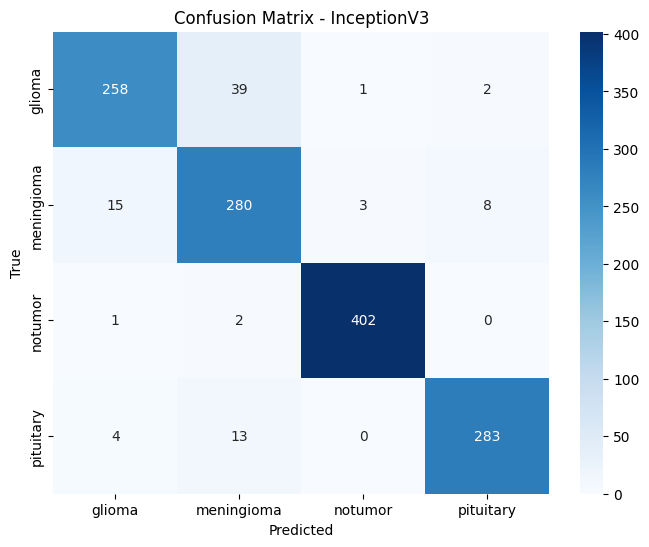

In [26]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model_incep.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - InceptionV3")
plt.show()


# Classification Report

In [27]:

print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      glioma       0.93      0.86      0.89       300
  meningioma       0.84      0.92      0.88       306
     notumor       0.99      0.99      0.99       405
   pituitary       0.97      0.94      0.95       300

    accuracy                           0.93      1311
   macro avg       0.93      0.93      0.93      1311
weighted avg       0.93      0.93      0.93      1311



# Training vs accuracy plot.

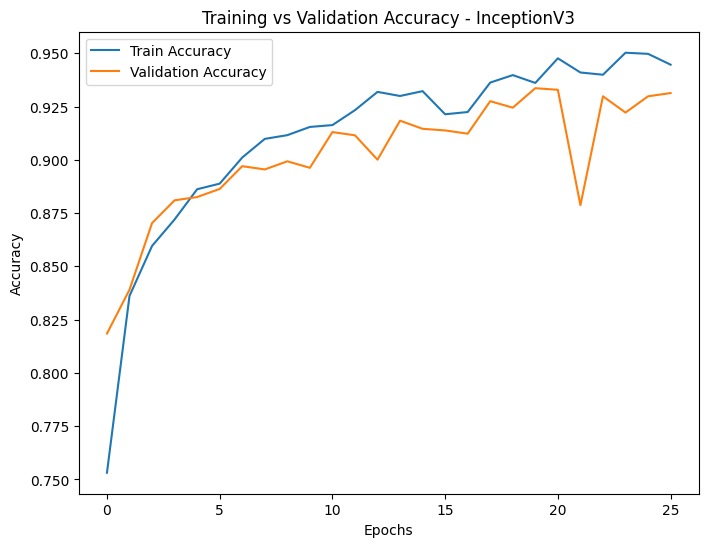

In [28]:
plt.figure(figsize=(8,6))
plt.plot(history_incep.history['accuracy'], label='Train Accuracy')
plt.plot(history_incep.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Training vs Validation Accuracy - InceptionV3")
plt.legend()
plt.show()

# Loss plot.

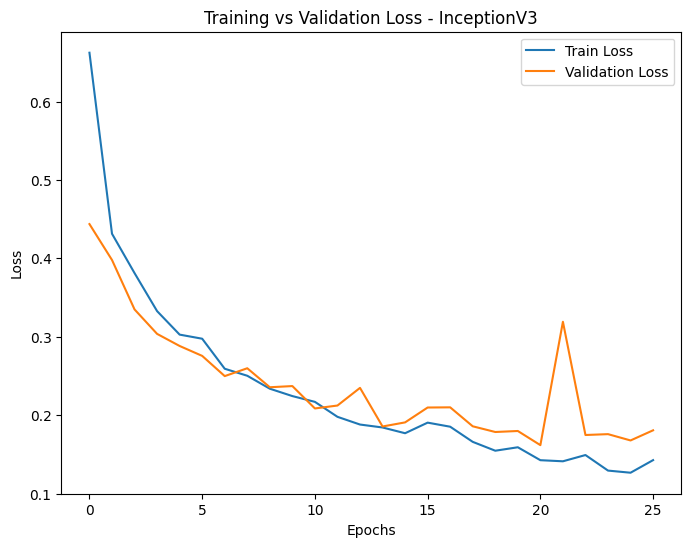

In [29]:
# --- Loss Plot (optional, useful to check overfitting) ---
plt.figure(figsize=(8,6))
plt.plot(history_incep.history['loss'], label='Train Loss')
plt.plot(history_incep.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title("Training vs Validation Loss - InceptionV3")
plt.legend()
plt.show()

# Inception model after Fine tuning.

# Unfrezing some layers and recompiling.

In [30]:
from tensorflow.keras import layers, models, optimizers

base_model_incep.trainable = True

fine_tune_at = len(base_model_incep.layers) - 50 #unfreezes only last ~50 layers
for layer in base_model_incep.layers[:fine_tune_at]:
    layer.trainable = False

# Recompile with lower learning rate
model_incep.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),  # lower lr for fine-tuning
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Fine tuning the model.

In [31]:
# Define callbacks again
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_incep_finetuned.h5",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)
# Fine-tune the model
history_incep_finetune = model_incep.fit(
    train_ds,
    validation_data=test_ds,
    epochs=30,              # try 20-30 for fine-tuning
    callbacks=[early_stop, checkpoint]
)

Epoch 1/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.8293 - loss: 0.4927
Epoch 1: val_accuracy improved from -inf to 0.92067, saving model to best_incep_finetuned.h5
179/179 ━━━━━━━━━━━━━━━━━━━━ 54s 160ms/step - accuracy: 0.8295 - loss: 0.4921 - val_accuracy: 0.9207 - val_loss: 0.2058
Epoch 2/30
178/179 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9286 - loss: 0.2017
Epoch 2: val_accuracy improved from 0.92067 to 0.92525, saving model to best_incep_finetuned.h5
179/179 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.9287 - loss: 0.2016 - val_accuracy: 0.9252 - val_loss: 0.1853
Epoch 3/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9471 - loss: 0.1470
Epoch 3: val_accuracy improved from 0.92525 to 0.93822, saving model to best_incep_finetuned.h5
179/179 ━━━━━━━━━━━━━━━━━━━━ 12s 65ms/step - accuracy: 0.9471 - loss: 0.1469 - val_accuracy: 0.9382 - val_loss: 0.1630
Epoch 4/30
178/179 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9575 - loss: 0.1140
Epoch 4: 

# Confusion matrix of Inception fine tuned model.

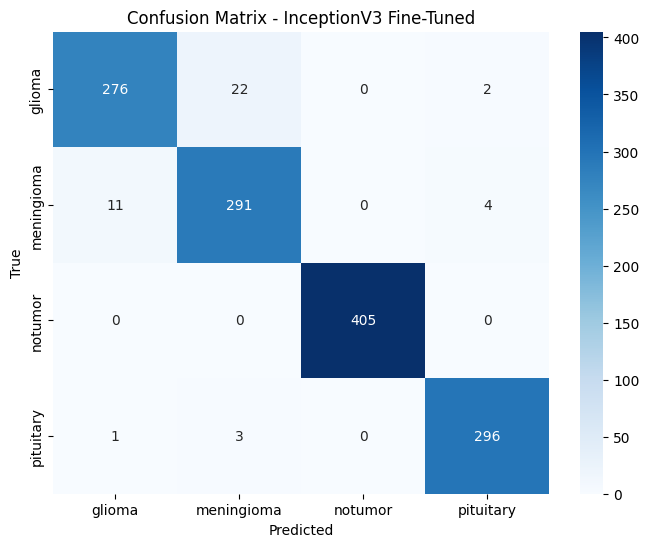

In [32]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model_incep.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))


# -----------------------------
# 3. Confusion Matrix
# -----------------------------
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - InceptionV3 Fine-Tuned")
plt.show()

# Classification report of Inception fine tuned model.

In [33]:

print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      glioma       0.96      0.92      0.94       300
  meningioma       0.92      0.95      0.94       306
     notumor       1.00      1.00      1.00       405
   pituitary       0.98      0.99      0.98       300

    accuracy                           0.97      1311
   macro avg       0.96      0.96      0.96      1311
weighted avg       0.97      0.97      0.97      1311



# Accuracy plot.

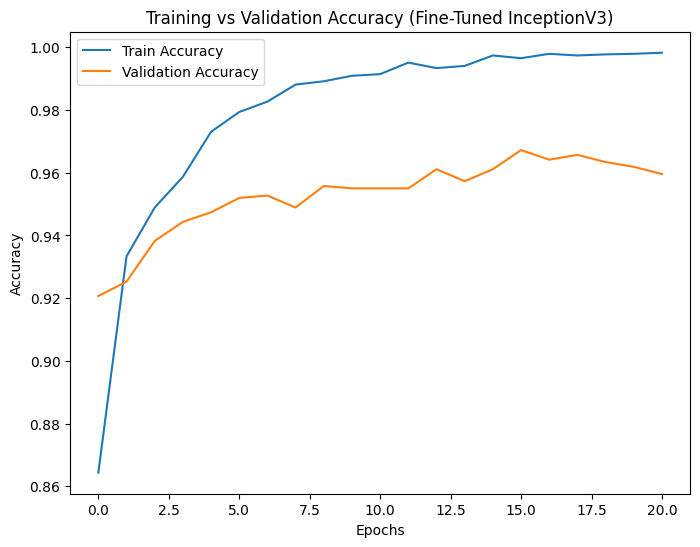

In [34]:

plt.figure(figsize=(8,6))
plt.plot(history_incep_finetune.history['accuracy'], label='Train Accuracy')
plt.plot(history_incep_finetune.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy (Fine-Tuned InceptionV3)')
plt.legend()
plt.show()

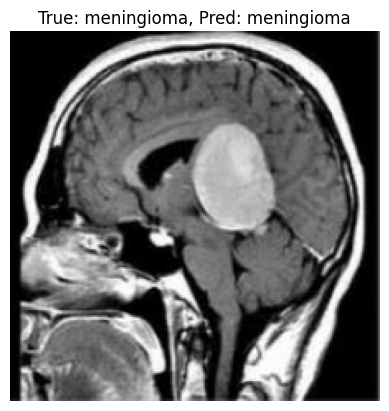

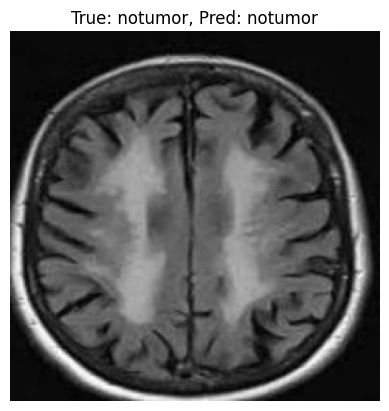

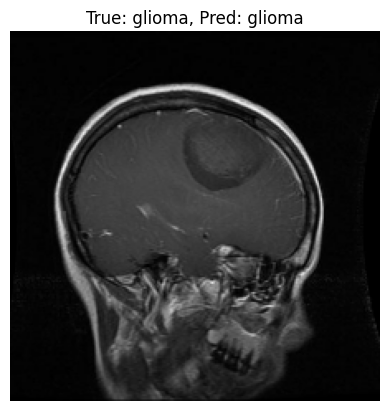

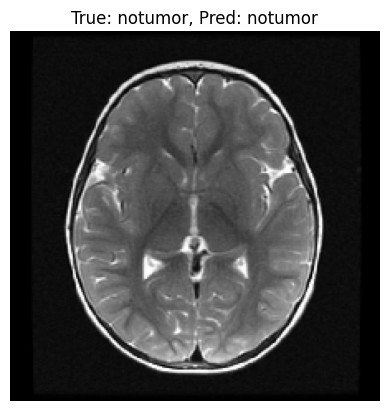

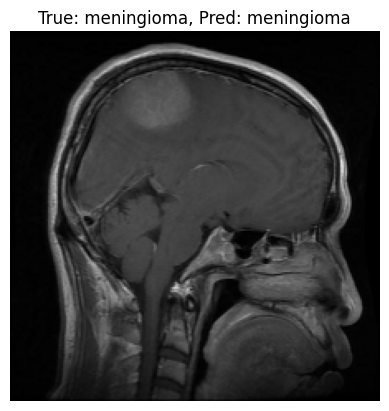

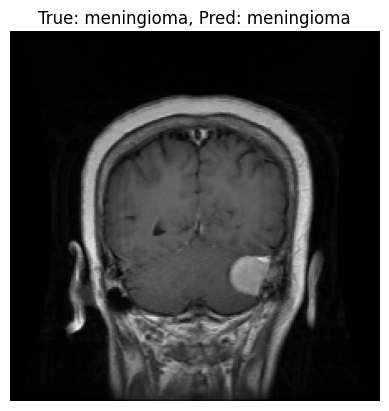

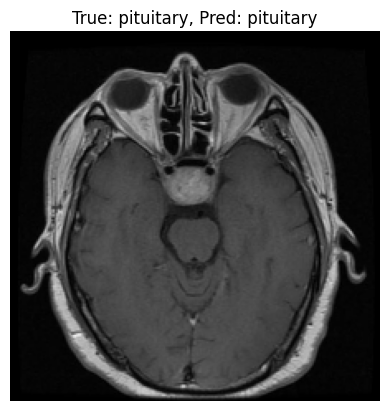

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Show 5–10 images one by one with predictions
for images, labels in test_ds.take(1):  
    preds = model_incep.predict(images, verbose=0)  # predictions from Inception
    
    for i in range(7):  # change to 5, 7, or 10
        img = (images[i].numpy() * 255).astype("uint8")  # rescale back for visualization
        true_label = class_names[np.argmax(labels[i].numpy())]
        pred_label = class_names[np.argmax(preds[i])]
        
        plt.imshow(img)
        plt.title(f"True: {true_label}, Pred: {pred_label}")
        plt.axis("off")
        plt.show()


# ResNet vs Inception Accuracy plot.

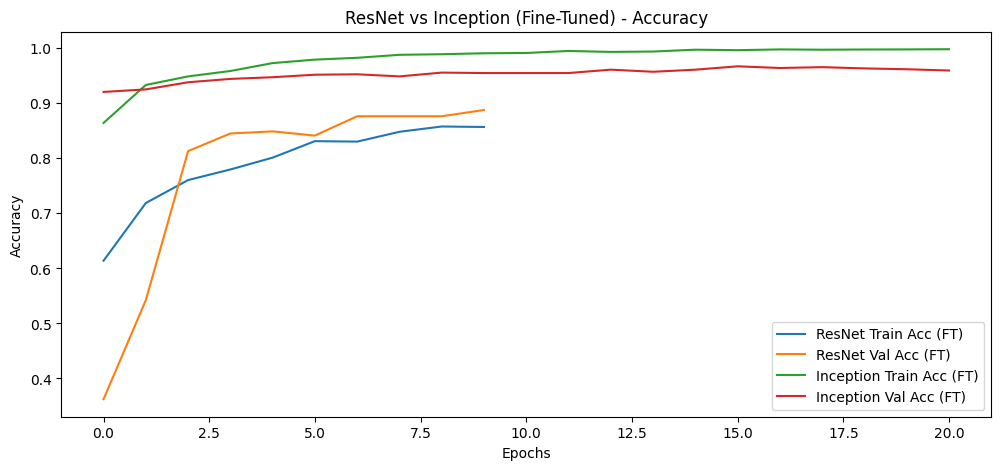

In [36]:
import matplotlib.pyplot as plt

# -----------------------------
# 1. Compare Accuracy (Fine-Tuned)
# -----------------------------
plt.figure(figsize=(12,5))

# ResNet Fine-Tuned Accuracy
plt.plot(history_finetune.history['accuracy'], label='ResNet Train Acc (FT)')
plt.plot(history_finetune.history['val_accuracy'], label='ResNet Val Acc (FT)')

# Inception Fine-Tuned Accuracy
plt.plot(history_incep_finetune.history['accuracy'], label='Inception Train Acc (FT)')
plt.plot(history_incep_finetune.history['val_accuracy'], label='Inception Val Acc (FT)')

plt.title("ResNet vs Inception (Fine-Tuned) - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Loss Plot, ResNet vs Inception.

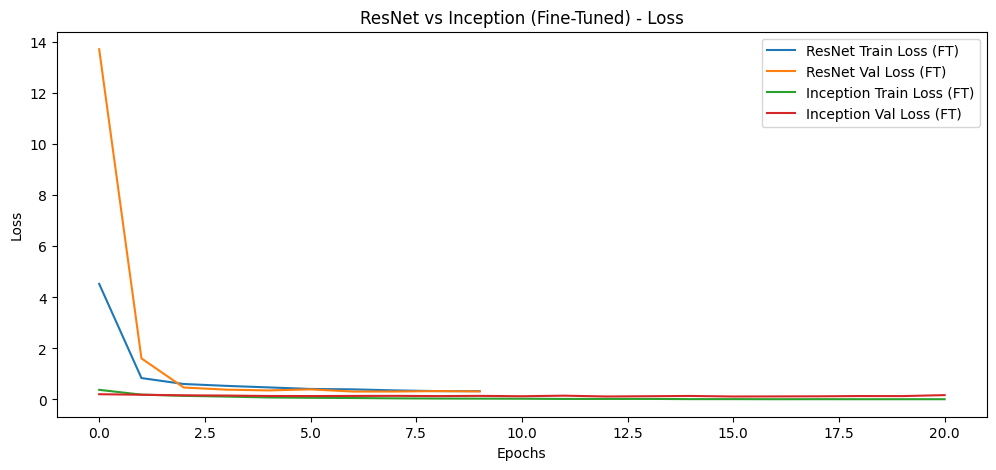

In [37]:
plt.figure(figsize=(12,5))

# ResNet Fine-Tuned Loss
plt.plot(history_finetune.history['loss'], label='ResNet Train Loss (FT)')
plt.plot(history_finetune.history['val_loss'], label='ResNet Val Loss (FT)')

# Inception Fine-Tuned Loss
plt.plot(history_incep_finetune.history['loss'], label='Inception Train Loss (FT)')
plt.plot(history_incep_finetune.history['val_loss'], label='Inception Val Loss (FT)')

plt.title("ResNet vs Inception (Fine-Tuned) - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()